In [ ]:
#####     Plot Pattern     #####
import numpy as np
from joblib import load, dump
from osgeo import gdal
gdal.UseExceptions()
rng = np.random.default_rng(seed=42)  # 随机数生成器

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
lat, lon = np.arange(-90, 90.1, 1), np.arange(0, 360.1, 1)  # 经纬度网格

import _calGlobal
factor = 1e-7  # 单位换算系数 (MgC/ha -> PgC)
def getGlobal(x, **kwargs):
    return _calGlobal.getGlobalSum(x, factor=factor, **kwargs)

def flipImage(tiff:np.ndarray):
    """Change image coordinate"""
    tiff = np.flip(tiff, axis=0)
    temp = np.zeros_like(tiff)
    temp[:, :180] = tiff[:, 180:]
    temp[:, 180:] = tiff[:, :180]
    tiff = temp
    return tiff

In [ ]:
### ----- Load ESACCI V7 / CMIP6 / Koppen ----- ###
ESA_2010 = load("./Data/ESACCI_2010.joblib")
ESA_2010std = load("./Data/ESACCI-std_2010.joblib")
ESA_2015 = load("./Data/ESACCI_2015.joblib")
ESA_2015std = load("./Data/ESACCI-std_2015.joblib")
ESA_data = np.mean(np.stack((ESA_2010, ESA_2015), axis=0), axis=0)  # (lat, lon)
ESA_std = np.mean([ESA_2010std, ESA_2015std], axis=0)  # (lat, lon)
#dump(ESA_data, "./Data/ESACCI_mean.joblib")

CMIP_set:dict = load("./Data/CMIPdata_5yr.joblib")
modelNum = len(CMIP_set)  # 模型数量：30
modelNames = list(CMIP_set.keys())
CMIP_list0, CMIP_listt = [], []  ### 原始数据 & treeFrac数据
for (i, j) in CMIP_set.values():
    CMIP_list0.append(i)
    if j is not None: CMIP_listt.append(j)
print(modelNum)
print(modelNames)

Koppen:np.ndarray = gdal.Open("./Data/Koppen_2010.tif", gdal.GA_ReadOnly).ReadAsArray()
Koppen = flipImage(Koppen.astype(np.float32))
#TreeCover:np.ndarray = gdal.Open("./Var/Veg/TreeCover.tif").ReadAsArray()
#TreeCover = flipImage(TreeCover.astype(np.float32))

# Set invalid to nan
ValidMask = (Koppen > 0) & (ESA_data > 0)  ### Valid Mask
Koppen[~ValidMask] = np.nan
ESA_data[~ValidMask] = np.nan
ESA_std[~ValidMask] = np.nan
ESA_2010[~ValidMask] = np.nan; ESA_2015[~ValidMask] = np.nan
for i in CMIP_list0: i[~ValidMask] = np.nan

30
['ACCESS-ESM1-5', 'BCC-CSM2-MR', 'BCC-ESM1', 'CanESM5', 'CESM2-FV2', 'CESM2-WACCM-FV2', 'CESM2-WACCM', 'CESM2', 'CMCC-CM2-SR5', 'CMCC-ESM2', 'CNRM-ESM2-1', 'E3SM-1-1-ECA', 'E3SM-1-1', 'EC-Earth3-CC', 'EC-Earth3-Veg-LR', 'GFDL-ESM4', 'INM-CM4-8', 'INM-CM5-0', 'IPSL-CM6A-LR-INCA', 'IPSL-CM6A-LR', 'KIOST-ESM', 'MPI-ESM-1-2-HAM', 'MPI-ESM1-2-LR', 'NorCPM1', 'NorESM2-LM', 'NorESM2-MM', 'SAM0-UNICON', 'TaiESM1', 'UKESM1-0-LL', 'UKESM1-1-LL']


Tree Fraction Threshold:  0.5


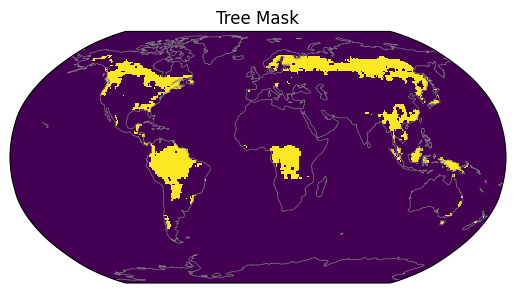

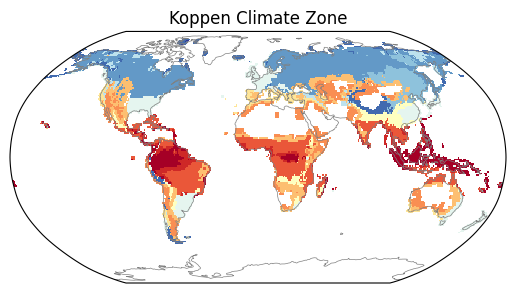

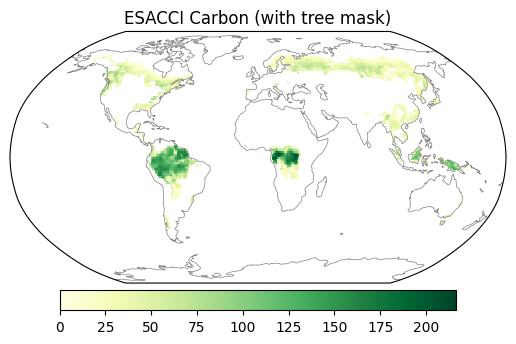

In [ ]:
### ----- Tree Mask ----- ###
CMIP_data0:np.ndarray = np.stack(CMIP_list0, axis=0)  # 原始数据 (N, lat, lon)
TreeFrac:np.ndarray = np.stack(CMIP_listt, axis=0)  # treeFrac (N, lat, lon)
TreeFrac[np.isnan(TreeFrac)] = 0.
TreeFrac = np.mean(TreeFrac, axis=0)  # treeFrac (lat, lon)

tree_thr = 0.5  # Tree Fraction threshold
print("Tree Fraction Threshold: ", tree_thr)
TreeMask = (TreeFrac >= tree_thr) & ValidMask  ###
#dump(ValidMask, "./validmask.joblib")
#dump(TreeMask, "./treemask.joblib")

ax = plt.axes(projection=ccrs.Robinson())
ax.set_global()
ax.coastlines(color="gray", linewidth=0.5)
img = ax.pcolormesh(lon, lat, TreeMask, transform=ccrs.PlateCarree(), shading="flat")
plt.title("Tree Mask")
plt.show()
plt.close()

# Apply tree mask, set invalid to nan
TreeMask = TreeMask.astype(np.float32)
TreeMask[TreeMask == 0] = np.nan
ESA_datat = ESA_data * TreeMask     # ESA obs data with tree mask
CMIP_datat = CMIP_data0 * TreeMask  # CMIP ESM data with tree mask

### ----- Climate Zone Mask ----- ###
cliDict = {
    "Af": [1],  # 热带雨林
    "Am": [2],  # 热带季风
    "Aw": [3],  # 热带萨瓦纳
    "BW": [4, 5], # 干旱沙漠
    "BS": [6, 7], # 半干旱草原
    "Cs": [8, 9, 10], # 亚热带夏干（地中海）
    "Cw": [11, 12, 13], # 亚热带冬干
    "Cf": [14, 15, 16], # 亚热带全湿
    "Ds": [17, 18, 19, 20], # 寒温带夏干
    "Dw": [21, 22, 23, 24], # 寒温带冬干
    "Df": [25, 26, 27, 28], # 寒温带全湿
    "ET": [29],  # 极地苔原
    "EF": [30]   # 极地冰原
    }
# f=全湿，s=夏干，w=冬干
cliMask = [np.isin(Koppen, ids) for ids in cliDict.values()] ### Climate Mask

ax = plt.axes(projection=ccrs.Robinson())
ax.set_global()
ax.coastlines(color="gray", linewidth=0.5)
temp = np.full_like(Koppen, np.nan)
for i in range(len(cliMask)):
    temp[cliMask[i]] = i
img = ax.pcolormesh(lon, lat, temp, cmap="RdYlBu", transform=ccrs.PlateCarree(), shading="flat")
plt.title("Koppen Climate Zone")
plt.show()
plt.close()

ax = plt.axes(projection=ccrs.Robinson())
ax.set_global()
ax.coastlines(color="gray", linewidth=0.5)
img = ax.pcolormesh(lon, lat, ESA_datat, vmin=0, cmap="YlGn", transform=ccrs.PlateCarree(), shading="flat")
plt.colorbar(img, ax=ax, orientation="horizontal", pad=0.02, shrink=0.8)
plt.title("ESACCI Carbon (with tree mask)")
plt.show()
plt.close()

ESA Mean:  200.9 PgC (285.7)
CMIP MME:  241.3 PgC ± 72.7 (425.2 ± 128.8)
 	Af	Am	Aw	BW	BS	Cs	Cw	Cf	Ds	Dw	Df	ET	EF
ESA:	61.73	37.92	31.27	0.03	0.68	1.85	5.99	9.21	1.21	6.89	43.95	0.19	0.00
CMIP6:	80.98	38.41	36.66	0.03	1.66	1.59	11.41	15.30	0.75	8.69	45.57	0.26	0.00
Diff:	19.25	0.49	5.38	-0.01	0.98	-0.26	5.42	6.09	-0.46	1.80	1.62	0.06	--
 	31.2%	1.3%	17.2%	-15.6%	144.2%	-14.1%	90.4%	66.1%	-37.8%	26.2%	3.7%	33.9%	--


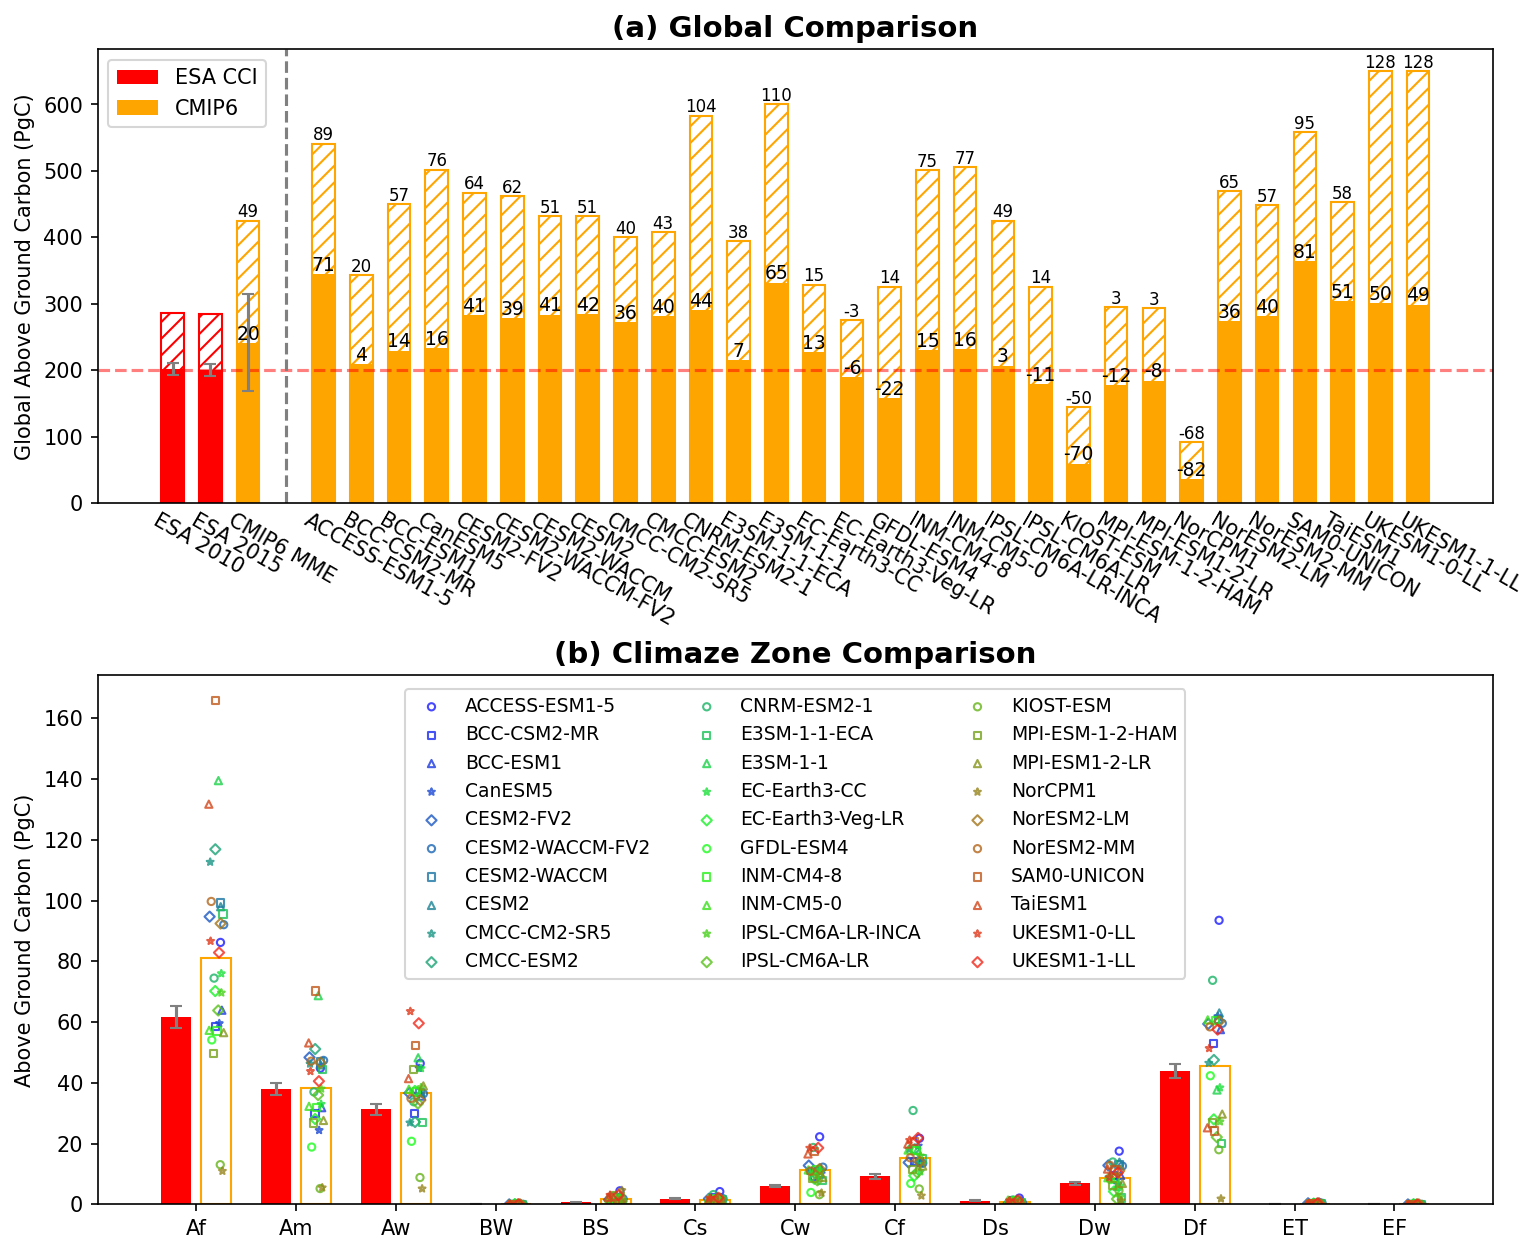

In [ ]:
### ----- Global Comparison ----- ###
fig, axs = plt.subplots(2, 1, figsize=(12, 10), dpi=150,
    gridspec_kw={"height_ratios":[3, 3.5], "hspace":0.35})
ax = axs[0]

### ESA CCI
esaSum0 = getGlobal(ESA_data)
esaSumt = getGlobal(ESA_datat)
ax.axhline(y=esaSumt, color="red", linestyle="--", alpha=0.5)
bar1_ = ax.bar([-3, -2], [getGlobal(ESA_2010), getGlobal(ESA_2015)],
               width=0.6, edgecolor="red", facecolor="none", hatch="///")
bar1t = ax.bar([-3, -2], [getGlobal(ESA_2010*TreeMask), getGlobal(ESA_2015*TreeMask)],
               width=0.6, color="red", label="ESA CCI")
ax.errorbar([-3, -2], [getGlobal(ESA_2010*TreeMask), getGlobal(ESA_2015*TreeMask)],
            yerr=[getGlobal(ESA_2010std*TreeMask), getGlobal(ESA_2015std*TreeMask)],
            color="gray", capsize=3, ls="none")

### CMIP6 Models
x2 = np.arange(1, modelNum+1)
y20 = list(map(getGlobal, CMIP_data0))
y2t = list(map(getGlobal, CMIP_datat))
bar20 = ax.bar(x2, y20, width=0.6, edgecolor="orange", facecolor="none", hatch="///")
bar2t = ax.bar(x2, y2t, width=0.6, color="orange", label="CMIP6")
### CMIP6 mean
cmipMean0, cmipMeant = np.mean(y20), np.mean(y2t)
bar30 = ax.bar(-1, cmipMean0, width=0.6, edgecolor="orange", facecolor="none", hatch="///")
bar3t = ax.bar(-1, cmipMeant, width=0.6, color="orange")
ax.errorbar(-1, cmipMeant, yerr=np.std(y2t), color="gray", capsize=3, ls="none")

### Diff percent
ax.axvline(x=0, color="gray", linestyle="--")
ax.text(-1, cmipMean0+5, f"{(cmipMean0-esaSum0)/esaSum0*100:.0f}", ha="center", fontsize=8)
ax.text(-1, cmipMeant+5, f"{(cmipMeant-esaSumt)/esaSumt*100:.0f}", ha="center", fontsize=9)
diff0 = (y20 - esaSum0) / esaSum0 * 100
difft = (y2t - esaSumt) / esaSumt * 100
for i in range(modelNum): ax.text(x2[i], y20[i]+5, f"{diff0[i]:.0f}", ha="center", fontsize=8)
for i in range(modelNum): ax.text(x2[i], y2t[i]+5, f"{difft[i]:.0f}", ha="center", fontsize=9)
shift = 0.6

ax.set_xticks([-3-shift,-2-shift,-1-shift]+list(x2-shift),
              labels=["ESA 2010","ESA 2015","CMIP6 MME"]+modelNames,
              rotation=-30, fontsize=10, ha="left")
ax.tick_params(axis="x", length=0)
ax.set_ylabel("Global Above Ground Carbon (PgC)")
ax.legend(loc="upper left")
ax.set_title("(a) Global Comparison", fontsize=14, weight="bold")

print(f"ESA Mean:  {esaSumt:.1f} PgC ({esaSum0:.1f})")
print(f"CMIP MME:  {cmipMeant:.1f} PgC ± {np.std(y2t):.1f} ({cmipMean0:.1f} ± {np.std(y20):.1f})")

### ---------- Climake Zone Comparison ---------- ###
CMIP_zone = [[] for _ in range(len(cliDict))] # (zone, N)
for CMIP_map in CMIP_datat:
    for i in range(len(cliMask)):
        temp = CMIP_map.copy()
        temp[~cliMask[i]] = np.nan
        CMIP_zone[i].append(getGlobal(temp))
CMIP_zone = np.array(CMIP_zone)

ax = axs[1]
x = np.arange(0, len(cliDict))

### Zone Mean
y1 = [getGlobal(ESA_datat, mask=mask) for mask in cliMask]
bar1 = ax.bar(x-0.2, y1, width=0.3, color="red")
stds = [getGlobal(ESA_std, mask=mask) for mask in cliMask]
ax.errorbar(x-0.2, y1, yerr=stds, color="gray", capsize=3, ls="none")

y2 = CMIP_zone.mean(axis=1)
bar2 = ax.bar(x+0.2, y2, width=0.3, facecolor="none", edgecolor="orange")

### scatter CMIP6 Models
# 配置渐变色和符号
from matplotlib.colors import LinearSegmentedColormap
colors = [(0.1, 0.1, 1.), (0.1, 1., 0.1), (1., 0.1, 0.1)]
cmap = LinearSegmentedColormap.from_list("mycmap", colors)
markers = ['o', 's', '^', '*', 'D']  # 圆圈、方块、三角形、星星、菱形
# 绘制所有点（按符号分组）
shift = rng.uniform(-0.08, 0.08, size=modelNum)  # 随机偏移避免重叠
for i in range(modelNum):
    color = cmap(i/modelNum, alpha=0.8)
    marker = markers[i%len(markers)]
    ax.scatter(x+0.2+shift[i], CMIP_zone[:,i], s=12,
               facecolor="none", edgecolor=color, marker=marker, label=modelNames[i])

### 模型图例
ax.legend(loc="center", bbox_to_anchor=(0.5, 0.7), ncol=3, fontsize=9)
ax.set_ylabel("Above Ground Carbon (PgC)")
ax.set_xticks(x, labels=cliDict.keys())
ax.set_title("(b) Climaze Zone Comparison", fontsize=14, weight="bold")

print("\t".join([" "] + list(cliDict.keys())))
print("\t".join(["ESA:"] + [f"{i:.2f}" for i in y1]))
print("\t".join(["CMIP6:"] + [f"{i:.2f}" for i in y2]))
print("\t".join(["Diff:"] + [f"{j-i:.2f}" if i!=0 else "--" for i,j in zip(y1,y2)]))
print("\t".join([" "] + [f"{(j-i)/i*100:.1f}%" if i!=0 else "--" for i,j in zip(y1,y2)]))
plt.show(fig)
plt.close()

C:\Users\17596\AppData\Local\Temp\ipykernel_8452\1337575026.py:28: RuntimeWarning: Mean of empty slice
  data = np.nanmean(CMIP_datat, axis=0)
C:\Users\17596\AppData\Local\Temp\ipykernel_8452\1337575026.py:11: RuntimeWarning: Mean of empty slice
  return np.nanmean(reshaped, axis=-1), np.nanstd(reshaped, axis=-1)
c:\Python312\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\17596\AppData\Local\Temp\ipykernel_8452\1337575026.py:11: RuntimeWarning: Mean of empty slice
  return np.nanmean(reshaped, axis=-1), np.nanstd(reshaped, axis=-1)
c:\Python312\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


Major Agreement: 1675 / 3571


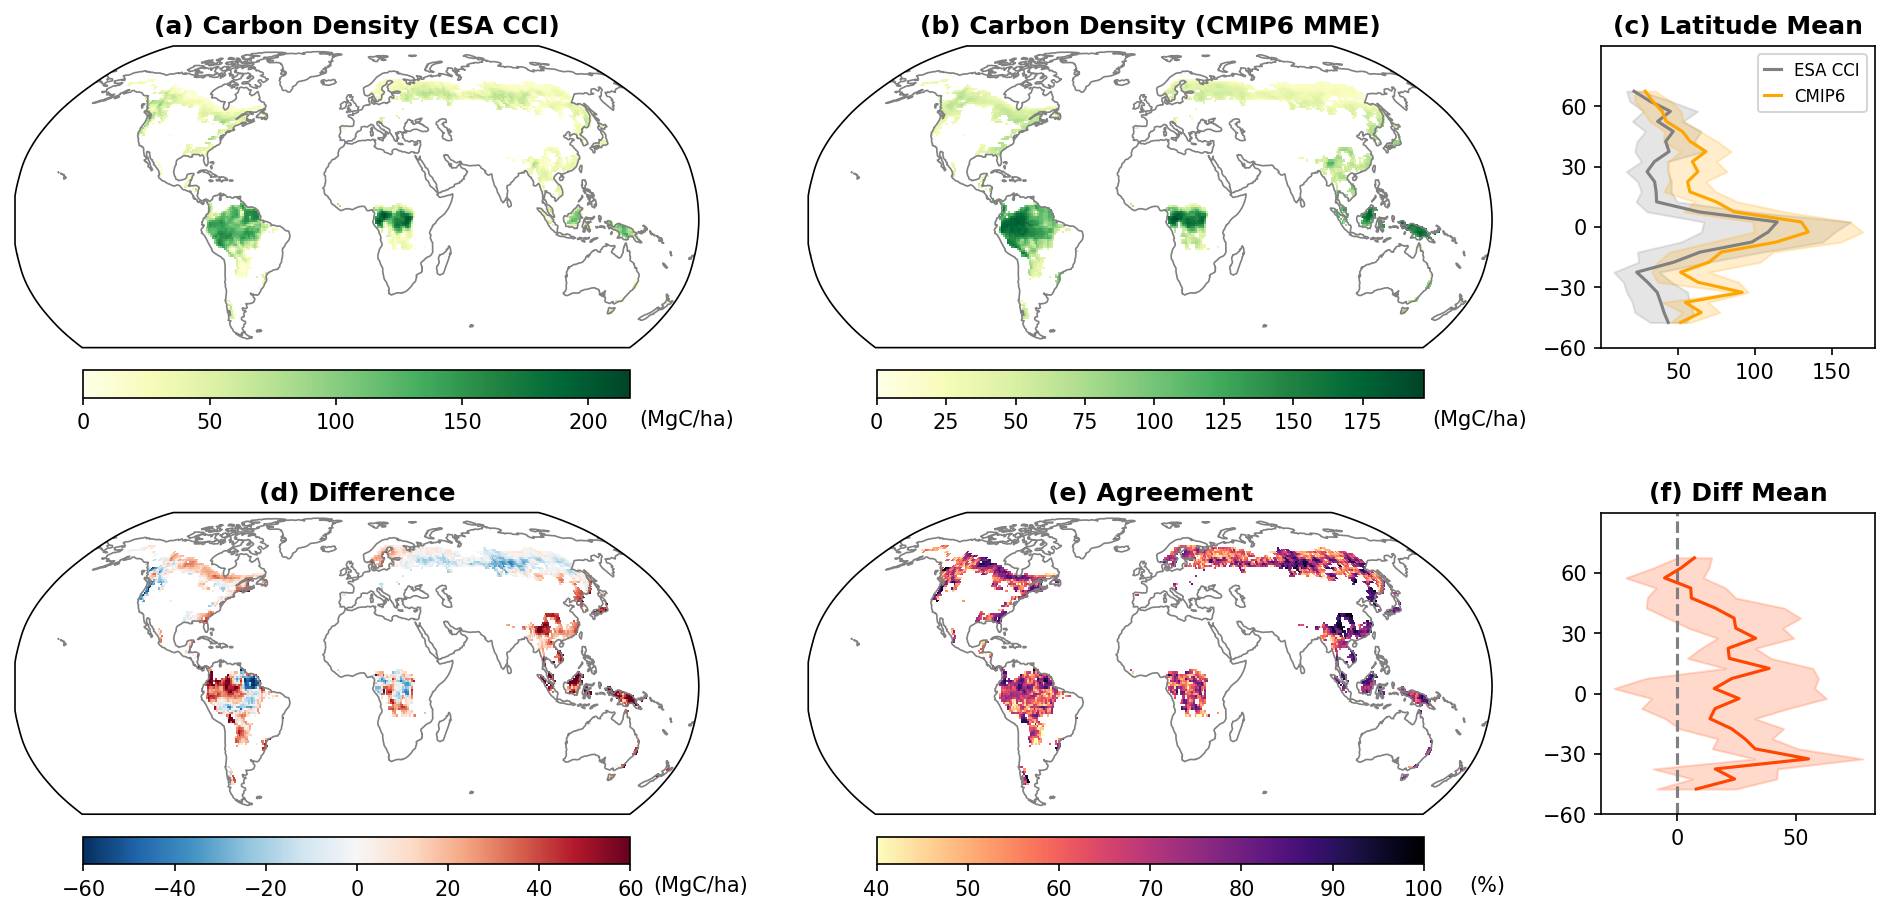

In [17]:
### ---------- Global Map ---------- ###
from matplotlib.gridspec import GridSpec

def get_lat_mean(arr:np.ndarray, group=3) -> tuple:
    """按纬度取平均，返回均值和标准差. (不考虑地球形变).\n
    Input shape: [lat, lon];  Output shape: [lat/group]
    """
    lat, lon = arr.shape
    if lat % group != 0: raise ValueError("lat %% group != 0")
    reshaped = arr.reshape(lat//group, -1)
    return np.nanmean(reshaped, axis=-1), np.nanstd(reshaped, axis=-1)

fig = plt.figure(figsize=(16, 8), dpi=150)
gs = GridSpec(2, 3, fig, width_ratios=[1, 1, 0.4], hspace=0.02)

### 只保留 60S ~ 90N
# ========== 上半部分子图 ========== #
### 左上：观测值 Map
ax1 = fig.add_subplot(gs[0, 0], projection=ccrs.Robinson())
img1 = ax1.pcolormesh(lon, lat[30:], ESA_datat[30:], vmin=0, cmap="YlGn",
                      transform=ccrs.PlateCarree(), shading="flat")  # 60S-90N
ax1.coastlines(color="gray", linewidth=0.8)
ax1.set_title("(a) Carbon Density (ESA CCI)", weight="bold")
cbar = fig.colorbar(img1, ax=ax1, orientation="horizontal", shrink=0.8, pad=0.05)
cbar.ax.text(220, -1, s="(MgC/ha)")

### 右上：CMIP mean Map
data = np.nanmean(CMIP_datat, axis=0)
ax2 = fig.add_subplot(gs[0, 1], projection=ccrs.Robinson())
img2 = ax2.pcolormesh(lon, lat[30:], data[30:], vmin=0, cmap="YlGn",
                      transform=ccrs.PlateCarree(), shading="flat")  # 60S-90N
ax2.coastlines(color="gray", linewidth=0.8)
ax2.set_title("(b) Carbon Density (CMIP6 MME)", weight="bold")
cbar = fig.colorbar(img2, ax=ax2, orientation="horizontal", shrink=0.8, pad=0.05)
cbar.ax.text(200, -1, s="(MgC/ha)")

### 纬度统计图
group = 5  ### 5°一个点
lat_range = np.arange(-60+group/2, 90, group)  # 60S-90N
ESA_lat, ESA_std = get_lat_mean(ESA_datat[30:], group=group)
CMIP_lat, CMIP_std = get_lat_mean(data[30:], group=group)

ax3 = fig.add_subplot(gs[0, 2])
xmin, xmax = ESA_lat-ESA_std, ESA_lat+ESA_std
ax3.plot(ESA_lat, lat_range, linestyle="-", color="gray", label="ESA CCI")  # 60S-90N
ax3.fill_betweenx(lat_range, xmin, xmax, color="gray", alpha=0.2)
xmin, xmax = CMIP_lat-CMIP_std, CMIP_lat+CMIP_std
ax3.plot(CMIP_lat, lat_range, linestyle="-", color="orange", label="CMIP6")  # 60S-90N
ax3.fill_betweenx(lat_range, xmin, xmax, color="orange", alpha=0.2)
pos1, pos3 = ax1.get_position(), ax3.get_position()
ax3.set_position([pos3.x0, pos1.y0, pos3.width, pos1.height])
ax3.set_ylim(-60, 90)  # 60S-90N
ax3.set_yticks(np.arange(-60, 61, 30))
ax3.legend(loc="best", fontsize=8, handlelength=1)
ax3.set_title("(c) Latitude Mean", weight="bold")

# ========== 下半部分子图 ========== #
### 左下：绝对值 Difference
diff = data - ESA_datat
ax4 = fig.add_subplot(gs[1, 0], projection=ccrs.Robinson())
img4 = ax4.pcolormesh(lon, lat[30:], diff[30:], vmin=-60, vmax=60, cmap="RdBu_r",
                      transform=ccrs.PlateCarree(), shading="flat")  # 60S-90N
ax4.coastlines(color="gray", linewidth=0.8)
ax4.set_title("(d) Difference", weight="bold")
cbar = fig.colorbar(img4, ax=ax4, orientation="horizontal", shrink=0.8, pad=0.05)
cbar.ax.text(65, -1, s="(MgC/ha)")

### 右下：Diff Agreement
agree = ((CMIP_datat - ESA_datat) * diff) > 0  # (N, lat, lon)
agree = np.mean(agree, axis=0) * 100
agree[np.isnan(diff)] = np.nan
ax5 = fig.add_subplot(gs[1, 1], projection=ccrs.Robinson())
img5 = ax5.pcolormesh(lon, lat[30:], agree[30:], vmin=40, vmax=100, cmap="magma_r",
                      transform=ccrs.PlateCarree(), shading="flat")  # 60S-90N
ax5.coastlines(color="gray", linewidth=0.8)
ax5.set_title("(e) Agreement", weight="bold")
cbar = fig.colorbar(img5, ax=ax5, orientation="horizontal", shrink=0.8, pad=0.05)
cbar.ax.text(105, -1, s="(%)")

agree_66 = np.sum(agree > 66.7)  # 66.7% 一致性
print(f"Major Agreement: {agree_66} / {np.sum(~np.isnan(agree))}")

### 纬度统计图
ax6 = fig.add_subplot(gs[0, 2])
ax6.axvline(x=0, color="gray", linestyle="--")
diff_lat, diff_std = get_lat_mean(diff[30:], group=group)
ax6.plot(diff_lat, lat_range, linestyle="-", color="orangered")
#ax6.plot(CMIP_lat-ESA_lat, lat_range, linestyle="--")
xmin, xmax = diff_lat-diff_std, diff_lat+diff_std
ax6.fill_betweenx(lat_range, xmin, xmax, color="orangered", alpha=0.2)
pos4, pos6 = ax4.get_position(), ax6.get_position()
ax6.set_position([pos6.x0, pos4.y0, pos6.width, pos4.height])
ax6.set_ylim(-60, 90)  # 60S-90N
ax6.set_yticks(np.arange(-60, 61, 30))
ax6.set_title("(f) Diff Mean", weight="bold")

#plt.suptitle("CMIP6 MME Mean", y=0.9, va="center")
plt.show(fig)
plt.close(fig)

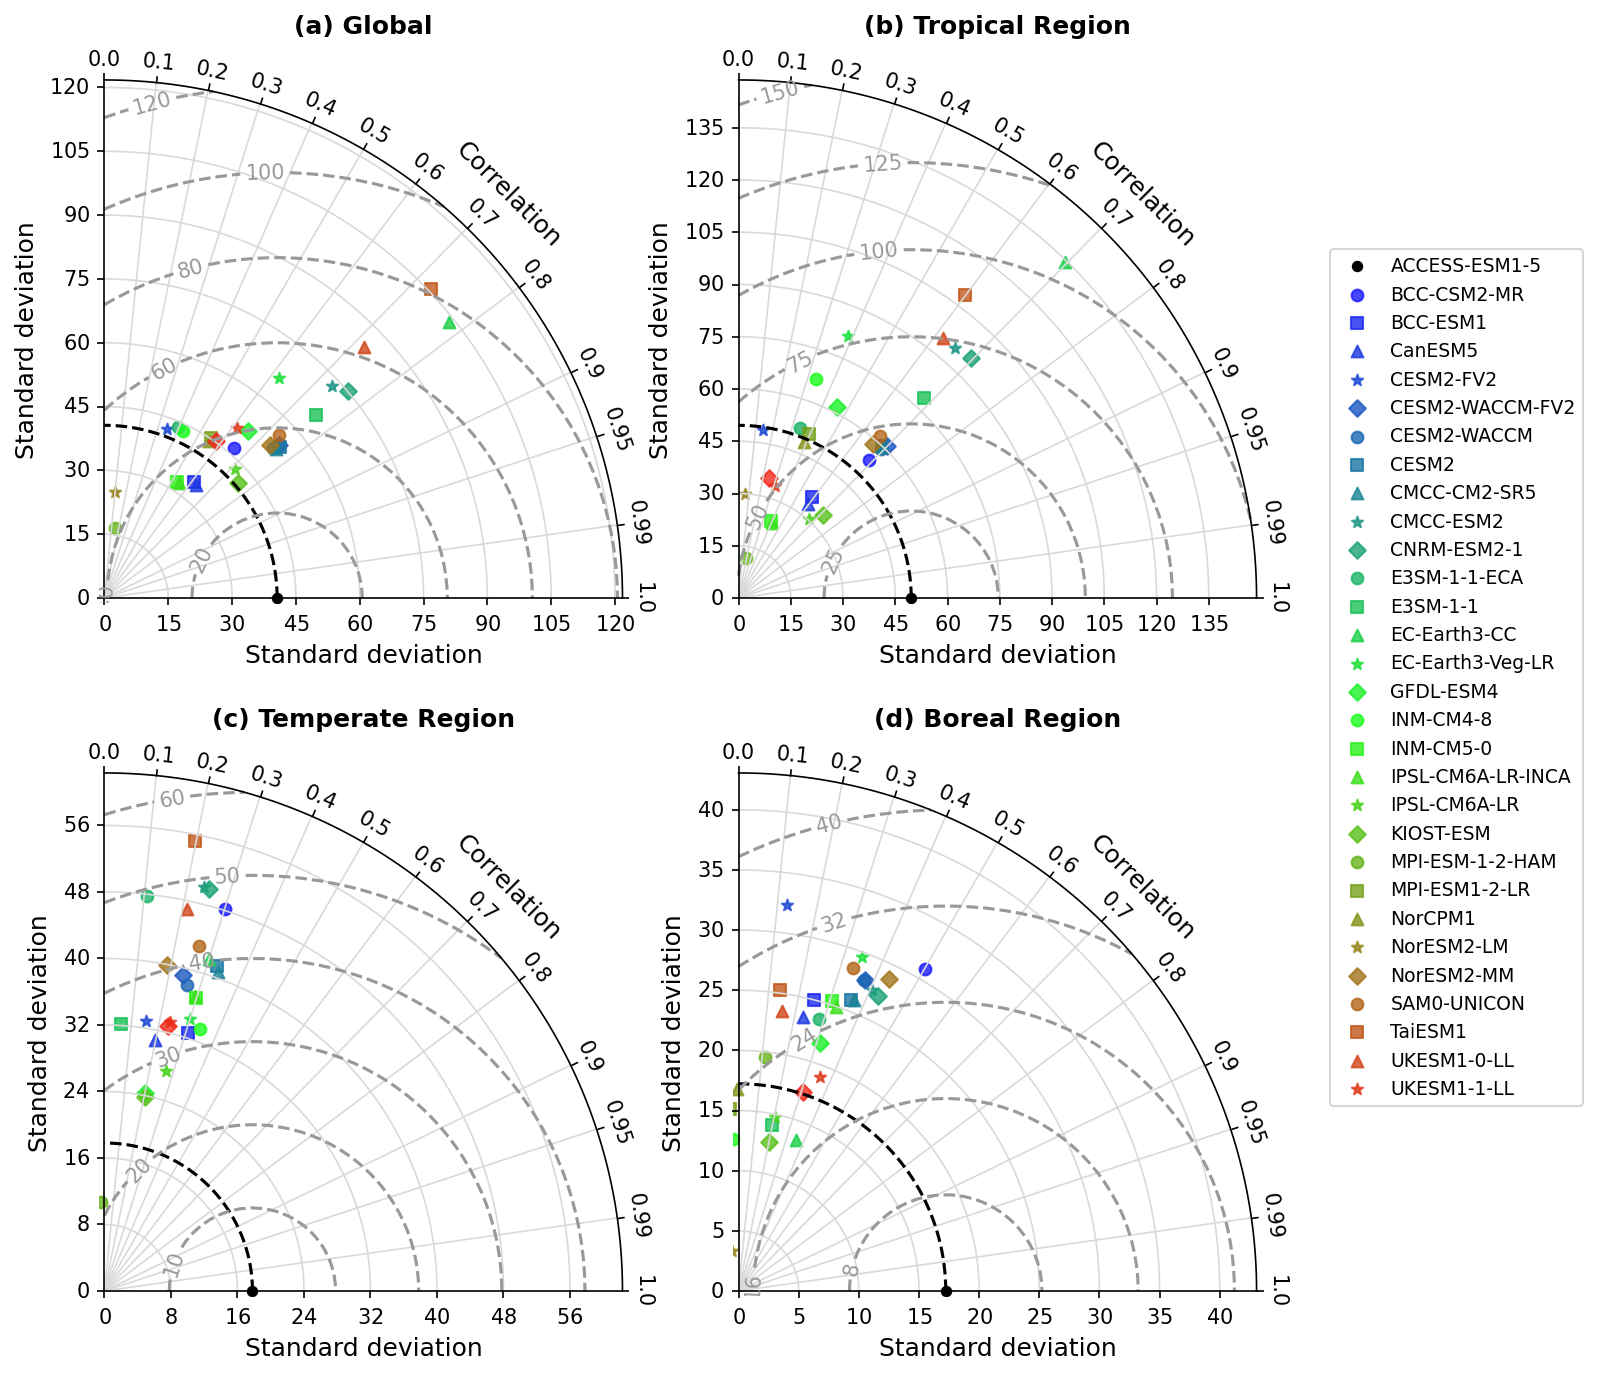

In [18]:
### ---------- Taylor Diagram ---------- ###
from taylorDiagram import TaylorDiagram
def plot_diagram(figure, rect=111, stdrange=3, mask=None, subtitle=""):
    if mask is not None: mask0 = (ESA_datat > 0) & mask
    else: mask0 = ESA_datat > 0
    refstd = np.std(ESA_datat[mask0])
    ### 绘制泰勒图
    diagram = TaylorDiagram(refstd, figure, rect, std_range=(0, stdrange))
    diagram.add_grid()
    diagram.add_RMSD(levels=6, fontsize=10)
    ax:plt.Axes = diagram._ax
    ### 添加样本点
    for i in range(modelNum):
        data = CMIP_datat[i]
        mask1 = mask0 & (data > 0)
        # 复用颜色和标记
        color = cmap(i/modelNum, alpha=0.8)
        marker = markers[i%len(markers)]
        # 绘制样本点
        stddev = np.nanstd(data[mask1])
        corrcoef = np.corrcoef(data[mask1], ESA_datat[mask1])[0, 1]
        diagram.add_sample(stddev, corrcoef, label=modelNames[i],
                    marker=marker, color=color, s=32)
    if subtitle:
        ax.set_title(subtitle, fontsize=12, pad=20, weight="bold")
    return diagram

# "Af", "Am", "Aw", "BW", "BS",
# "Cs", "Cw", "Cf", "Ds", "Dw", "Df", "ET", "EF"
fig = plt.figure(figsize=(10, 11), dpi=150)
dia = plot_diagram(fig, 221, subtitle="(a) Global")
mask_zone = cliMask[0] | cliMask[1] | cliMask[2]
dia = plot_diagram(fig, 222, mask=mask_zone, subtitle="(b) Tropical Region")
mask_zone = cliMask[5] | cliMask[6] | cliMask[7]
dia = plot_diagram(fig, 223, mask=mask_zone, stdrange=3.5, subtitle="(c) Temperate Region")
mask_zone = cliMask[8] | cliMask[9] | cliMask[10]
dia = plot_diagram(fig, 224, mask=mask_zone, stdrange=2.5, subtitle="(d) Boreal Region")

fig.legend(dia.get_handles(), modelNames, loc="center", bbox_to_anchor=(1.03, 0.5), fontsize=9)
#fig.suptitle("Taylor Diagram", fontsize=14, ha='center', y=0.93)
plt.show(fig)
plt.close(fig)